In [2]:

import pandas as pd


# STEP 1: IMPORT AND LOAD DATASET


# Location of our January 2019 sales file
file_path = "/Users/sidkulkarni/Desktop/supply-chain-portfolio/kaggle-raw-data/electronics - monthly-sales-2019/Sales_January_2019.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Show the first 5 rows
print("First 5 rows of dataset:")
display(df.head())



# STEP 2: UNDERSTAND DATASET STRUCTURE


# Display basic dataset information
print("\nRows and columns:", df.shape)
print("Column names:", df.columns.tolist())

# Check column data types
print("\nColumn data types:")
print(df.dtypes)



# STEP 3: INITIAL DATA QUALITY ASSESSMENT


# Check for missing information
print("\nMissing values by column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Count rows with at least one missing value
print("\nRows with missing data:")
print(df.isna().any(axis=1).sum())

# Count rows where every column is empty
print("\nCompletely empty rows:")
print(df.isna().all(axis=1).sum())

# Check whether column headers appear inside the data
print("\nRepeated header rows:")
print(df["Order ID"].eq("Order ID").sum())

# Display sample rows containing missing data
print("\nExamples of missing data:")
display(df[df.isna().any(axis=1)].head())



# STEP 4: CREATE A WORKING COPY FOR CLEANING


# Preserve the original dataset
df_clean = df.copy()

# Identify completely empty rows
empty_rows = df_clean.isna().all(axis=1)

# Identify repeated column headers
header_rows = (
    df_clean["Order ID"]
    .astype("string")
    .str.strip()
    .eq("Order ID")
    .fillna(False)
)

# Display records identified for removal
print("\nCompletely empty rows:", empty_rows.sum())
print("Repeated header rows:", header_rows.sum())



# STEP 5: REMOVE INVALID RECORDS


# Remove completely empty rows and repeated headers
df_clean = df_clean.loc[
    ~(empty_rows | header_rows)
].copy()

# Reset row numbering
df_clean.reset_index(drop=True, inplace=True)



# STEP 6: VALIDATE INITIAL CLEANING RESULTS


print("\n===== DATA CLEANING SUMMARY =====")

print("Original rows:", len(df))
print("Remaining rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining duplicate rows:")
print(df_clean.duplicated().sum())

print("\nColumn data types after initial cleaning:")
print(df_clean.dtypes)

# Display the cleaned dataset
print("\nFirst 5 rows after cleaning:")
display(df_clean.head())


# STEP 7: INVESTIGATE DUPLICATE TRANSACTIONS

# Find every row belonging to a duplicate group
duplicate_records = df_clean[
    df_clean.duplicated(keep=False)
]

# Count records involved in duplication
print("Rows involved in duplication:", len(duplicate_records))

# Count extra duplicate records
print("Extra duplicate rows:", df_clean.duplicated().sum())

# Display duplicate records
display(
    duplicate_records.sort_values("Order ID").head(30)
)

# STEP 8: REMOVE CONFIRMED DUPLICATE COPIES

# Create another copy to preserve previous cleaning results
df_dedup = df_clean.copy()

# Remove extra identical rows, keeping the first occurrence
df_dedup = df_dedup.drop_duplicates().reset_index(drop=True)

# Display cleaning results
print("Rows before duplicate removal:", len(df_clean))
print("Rows after duplicate removal:", len(df_dedup))
print("Duplicate rows removed:", len(df_clean) - len(df_dedup))

# Verify no exact duplicates remain
print("Remaining exact duplicates:", df_dedup.duplicated().sum())

# Preview the updated dataset
display(df_dedup.head())


# STEP 9: CONVERT COLUMNS TO CORRECT DATA TYPES

# Create a new working copy
df_typed = df_dedup.copy()

# Convert quantity ordered into numbers
df_typed["Quantity Ordered"] = pd.to_numeric(
    df_typed["Quantity Ordered"], errors="coerce"
)

# Convert price into numbers
df_typed["Price Each"] = pd.to_numeric(
    df_typed["Price Each"], errors="coerce"
)

# Convert order date into a date/time format
df_typed["Order Date"] = pd.to_datetime(
    df_typed["Order Date"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

# Check the updated data types
print("Updated column data types:")
print(df_typed.dtypes)

# Check whether any conversions failed
print("\nMissing values after conversion:")
print(df_typed[
    ["Quantity Ordered", "Price Each", "Order Date"]
].isna().sum())

# Preview the updated dataset
print("\nPreview of converted data:")
display(df_typed.head())


# STEP 10: ANALYZE JANUARY 2019 PRODUCT SALES

# Create a new working copy
df_sales = df_typed.copy()

# Calculate revenue for each transaction line
df_sales["Revenue"] = (
    df_sales["Quantity Ordered"] *
    df_sales["Price Each"]
)

# Group sales by product
product_summary = (
    df_sales.groupby("Product")
    .agg(
        Total_Units=("Quantity Ordered", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Order_Lines=("Order ID", "count")
    )
    .sort_values("Total_Units", ascending=False)
)

# Display the 10 bestselling products
print("TOP 10 PRODUCTS BY UNITS SOLD:")
display(product_summary.head(10))

# Check the overall dataset date range
print("Earliest sale:", df_sales["Order Date"].min())
print("Latest sale:", df_sales["Order Date"].max())


# STEP 11: INVESTIGATE TRANSACTION DATE COVERAGE

# Count how many transaction records belong to each month
monthly_counts = (
    df_sales["Order Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("Transaction records by calendar month:")
print(monthly_counts)

# Display transactions outside January 2019
outside_january = df_sales[
    df_sales["Order Date"].dt.to_period("M") != "2019-01"
]

print("\nRecords outside January:", len(outside_january))

print("\nExamples of transactions outside January:")
display(outside_january.head())


# STEP 12: COMBINE ALL 12 MONTHLY SALES FILES

import pandas as pd
from pathlib import Path

# Folder containing all 12 monthly CSV files
data_folder = Path(
    "/Users/sidkulkarni/Desktop/supply-chain-portfolio/"
    "kaggle-raw-data/electronics - monthly-sales-2019"
)

# Find all monthly CSV files
csv_files = sorted(data_folder.glob("Sales_*_2019.csv"))

print("Number of CSV files found:", len(csv_files))

# Check that we found exactly 12 files
if len(csv_files) != 12:
    raise ValueError("Expected 12 monthly files. Check the folder.")

# Create an empty list to hold our datasets
monthly_data = []

# Read each CSV file
for file in csv_files:
    monthly_df = pd.read_csv(file)

    # Keep track of which file each row came from
    monthly_df["Source_File"] = file.name

    monthly_data.append(monthly_df)

# Combine all monthly datasets into one DataFrame
df_2019_raw = pd.concat(
    monthly_data, ignore_index=True
)

# Display the results
print("\n===== ANNUAL DATASET SUMMARY =====")
print("Files combined:", len(csv_files))
print("Total raw rows:", len(df_2019_raw))
print("Total columns:", len(df_2019_raw.columns))

print("\nFirst 5 rows:")
display(df_2019_raw.head())

print("\nSource files:")
for file in csv_files:
    print(file.name)


First 5 rows of dataset:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,141234,iPhone,1,700,01/22/19 21:25,"944 Walnut St, Boston, MA 02215"
1,141235,Lightning Charging Cable,1,14.95,01/28/19 14:15,"185 Maple St, Portland, OR 97035"
2,141236,Wired Headphones,2,11.99,01/17/19 13:33,"538 Adams St, San Francisco, CA 94016"
3,141237,27in FHD Monitor,1,149.99,01/05/19 20:33,"738 10th St, Los Angeles, CA 90001"
4,141238,Wired Headphones,1,11.99,01/25/19 11:59,"387 10th St, Austin, TX 73301"



Rows and columns: (9723, 6)
Column names: ['Order ID', 'Product', 'Quantity Ordered', 'Price Each', 'Order Date', 'Purchase Address']

Column data types:
Order ID            str
Product             str
Quantity Ordered    str
Price Each          str
Order Date          str
Purchase Address    str
dtype: object

Missing values by column:
Order ID            26
Product             26
Quantity Ordered    26
Price Each          26
Order Date          26
Purchase Address    26
dtype: int64

Duplicate rows:
50

Rows with missing data:
26

Completely empty rows:
26

Repeated header rows:
16

Examples of missing data:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
664,NaN,NaN,NaN,NaN,NaN,NaN
678,NaN,NaN,NaN,NaN,NaN,NaN
797,NaN,NaN,NaN,NaN,NaN,NaN
876,NaN,NaN,NaN,NaN,NaN,NaN
1299,NaN,NaN,NaN,NaN,NaN,NaN



Completely empty rows: 26
Repeated header rows: 16

===== DATA CLEANING SUMMARY =====
Original rows: 9723
Remaining rows: 9681
Rows removed: 42

Remaining missing values:
Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
dtype: int64

Remaining duplicate rows:
10

Column data types after initial cleaning:
Order ID            str
Product             str
Quantity Ordered    str
Price Each          str
Order Date          str
Purchase Address    str
dtype: object

First 5 rows after cleaning:


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_66012/999367831.py:94: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.reset_index(drop=True, inplace=True)


... (10 outputs left out)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Revenue
4177,145212,Lightning Charging Cable,1,14.95,2019-02-01 00:36:00,"484 6th St, Dallas, TX 75001",14.95
4342,145372,AAA Batteries (4-pack),1,2.99,2019-02-01 04:02:00,"459 West St, Dallas, TX 75001",2.99
5450,146442,USB-C Charging Cable,1,11.95,2019-02-01 01:48:00,"229 West St, Los Angeles, CA 90001",11.95
6356,147309,Macbook Pro Laptop,1,1700.00,2019-02-01 01:01:00,"594 South St, Dallas, TX 75001",1700.00
6727,147663,Lightning Charging Cable,1,14.95,2019-02-01 00:33:00,"96 Elm St, Boston, MA 02215",14.95


Number of CSV files found: 12

===== ANNUAL DATASET SUMMARY =====
Files combined: 12
Total raw rows: 186850
Total columns: 7

First 5 rows:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,NaN,NaN,NaN,NaN,NaN,NaN,Sales_April_2019.csv
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv



Source files:
Sales_April_2019.csv
Sales_August_2019.csv
Sales_December_2019.csv
Sales_February_2019.csv
Sales_January_2019.csv
Sales_July_2019.csv
Sales_June_2019.csv
Sales_March_2019.csv
Sales_May_2019.csv
Sales_November_2019.csv
Sales_October_2019.csv
Sales_September_2019.csv


In [3]:

# ============================================================
# STEP 13: INITIAL CLEANING OF FULL-YEAR DATASET
# ============================================================

# Original sales columns (excluding Source_File)
sales_cols = [
    "Order ID",
    "Product",
    "Quantity Ordered",
    "Price Each",
    "Order Date",
    "Purchase Address"
]

# Create a working copy
df_2019_clean = df_2019_raw.copy()

# Identify completely empty transaction rows
empty_rows = (
    df_2019_clean[sales_cols]
    .isna()
    .all(axis=1)
)

# Identify repeated column headers
header_rows = (
    df_2019_clean["Order ID"]
    .astype("string")
    .str.strip()
    .eq("Order ID")
    .fillna(False)
)

# Show what we found
print("===== ANNUAL DATA QUALITY CHECK =====")
print("Original rows:", len(df_2019_clean))
print("Completely empty rows:", empty_rows.sum())
print("Repeated header rows:", header_rows.sum())

# Remove empty rows and repeated headers
df_2019_clean = df_2019_clean.loc[
    ~(empty_rows | header_rows)
].copy()

# Reset row numbering
df_2019_clean = df_2019_clean.reset_index(drop=True)

# Check for duplicates across the six sales columns
# Do not include Source_File in the duplicate comparison
duplicate_count = df_2019_clean.duplicated(
    subset=sales_cols
).sum()

print("\n===== INITIAL CLEANING SUMMARY =====")
print("Original rows:", len(df_2019_raw))
print("Rows remaining:", len(df_2019_clean))
print("Rows removed:", len(df_2019_raw) - len(df_2019_clean))
print("Potential duplicate rows:", duplicate_count)

print("\nMissing values after initial cleaning:")
print(df_2019_clean[sales_cols].isna().sum())

# Preview the working dataset
display(df_2019_clean.head())


===== ANNUAL DATA QUALITY CHECK =====
Original rows: 186850
Completely empty rows: 545
Repeated header rows: 355

===== INITIAL CLEANING SUMMARY =====
Original rows: 186850
Rows remaining: 185950
Rows removed: 900
Potential duplicate rows: 264

Missing values after initial cleaning:
Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
dtype: int64


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
2,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
3,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176561,Wired Headphones,1,11.99,04/30/19 09:27,"333 8th St, Los Angeles, CA 90001",Sales_April_2019.csv


In [4]:

# STEP 14: INVESTIGATE ANNUAL DUPLICATE RECORDS

# Find all records belonging to duplicate groups
duplicate_records_2019 = df_2019_clean[
    df_2019_clean.duplicated(
        subset=sales_cols,
        keep=False
    )
].copy()

# Count all extra duplicate records
print("Total extra duplicate rows:")
print(
    df_2019_clean.duplicated(
        subset=sales_cols
    ).sum()
)

# Count extra duplicates within the same monthly CSV
print("\nExtra duplicates within the same source file:")
print(
    df_2019_clean.duplicated(
        subset=sales_cols + ["Source_File"]
    ).sum()
)

# Count duplicate groups appearing in multiple source files
cross_file_groups = (
    duplicate_records_2019
    .groupby(sales_cols)["Source_File"]
    .nunique()
)

print("\nDuplicate groups found across multiple CSV files:")
print((cross_file_groups > 1).sum())

# Display sample duplicate records with their source files
print("\nExamples of duplicate records:")
display(
    duplicate_records_2019
    .sort_values(["Order ID", "Source_File"])
    .head(20)
)


Total extra duplicate rows:
264

Extra duplicates within the same source file:
264

Duplicate groups found across multiple CSV files:
0

Examples of duplicate records:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
68092,142071,AA Batteries (4-pack),1,3.84,01/17/19 23:02,"131 2nd St, Boston, MA 02215",Sales_January_2019.csv
68093,142071,AA Batteries (4-pack),1,3.84,01/17/19 23:02,"131 2nd St, Boston, MA 02215",Sales_January_2019.csv
71326,145143,Lightning Charging Cable,1,14.95,01/06/19 03:01,"182 Jefferson St, San Francisco, CA 94016",Sales_January_2019.csv
71327,145143,Lightning Charging Cable,1,14.95,01/06/19 03:01,"182 Jefferson St, San Francisco, CA 94016",Sales_January_2019.csv
73005,146765,Google Phone,1,600,01/21/19 11:23,"918 Highland St, New York City, NY 10001",Sales_January_2019.csv
73006,146765,Google Phone,1,600,01/21/19 11:23,"918 Highland St, New York City, NY 10001",Sales_January_2019.csv
73997,147707,Wired Headphones,1,11.99,01/04/19 16:50,"883 4th St, Dallas, TX 75001",Sales_January_2019.csv
73998,147707,Wired Headphones,1,11.99,01/04/19 16:50,"883 4th St, Dallas, TX 75001",Sales_January_2019.csv
75321,148984,USB-C Charging Cable,1,11.95,01/08/19 17:36,"562 14th St, Boston, MA 02215",Sales_January_2019.csv
75322,148984,USB-C Charging Cable,1,11.95,01/08/19 17:36,"562 14th St, Boston, MA 02215",Sales_January_2019.csv


In [5]:

# STEP 15: REMOVE ANNUAL DUPLICATE RECORDS


# Create a separate working copy
df_2019_dedup = df_2019_clean.copy()

# Remove duplicate records using the six sales columns
# Keep the first occurrence of each transaction
df_2019_dedup = df_2019_dedup.drop_duplicates(
    subset=sales_cols,
    keep="first"
).reset_index(drop=True)

# Display cleaning results
print("===== ANNUAL DEDUPLICATION SUMMARY =====")

print("Rows before:", len(df_2019_clean))
print("Rows after:", len(df_2019_dedup))

print(
    "Duplicate copies removed:",
    len(df_2019_clean) - len(df_2019_dedup)
)

# Verify no duplicate records remain
print(
    "Remaining duplicates:",
    df_2019_dedup.duplicated(subset=sales_cols).sum()
)

# Show the first five records
display(df_2019_dedup.head())


===== ANNUAL DEDUPLICATION SUMMARY =====
Rows before: 185950
Rows after: 185686
Duplicate copies removed: 264
Remaining duplicates: 0


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
2,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
3,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176561,Wired Headphones,1,11.99,04/30/19 09:27,"333 8th St, Los Angeles, CA 90001",Sales_April_2019.csv


In [6]:

# STEP 16: CONVERT ANNUAL DATA TYPES

# Create a new working copy
df_2019_typed = df_2019_dedup.copy()

# Convert quantities to numbers
df_2019_typed["Quantity Ordered"] = pd.to_numeric(
    df_2019_typed["Quantity Ordered"],
    errors="coerce"
)

# Convert prices to numbers
df_2019_typed["Price Each"] = pd.to_numeric(
    df_2019_typed["Price Each"],
    errors="coerce"
)

# Convert order dates to datetime
df_2019_typed["Order Date"] = pd.to_datetime(
    df_2019_typed["Order Date"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

# Check data types
print("===== UPDATED COLUMN DATA TYPES =====")
print(df_2019_typed.dtypes)

# Check for failed conversions
print("\n===== FAILED CONVERSIONS =====")
print(
    df_2019_typed[
        ["Quantity Ordered", "Price Each", "Order Date"]
    ].isna().sum()
)

# Check actual date coverage
print("\n===== TRANSACTION DATE RANGE =====")
print("Earliest sale:", df_2019_typed["Order Date"].min())
print("Latest sale:", df_2019_typed["Order Date"].max())

# Preview the result
print("\nFirst five records:")
display(df_2019_typed.head())


===== UPDATED COLUMN DATA TYPES =====
Order ID                       str
Product                        str
Quantity Ordered             int64
Price Each                 float64
Order Date          datetime64[us]
Purchase Address               str
Source_File                    str
dtype: object

===== FAILED CONVERSIONS =====
Quantity Ordered    0
Price Each          0
Order Date          0
dtype: int64

===== TRANSACTION DATE RANGE =====
Earliest sale: 2019-01-01 03:07:00
Latest sale: 2020-01-01 05:13:00

First five records:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
2,176560,Google Phone,1,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
3,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Sales_April_2019.csv


In [7]:

# STEP 17: VALIDATE ANNUAL TRANSACTION DATES

# Count transactions by calendar month
monthly_counts = (
    df_2019_typed["Order Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("===== TRANSACTIONS BY MONTH =====")
print(monthly_counts)

# Find records outside calendar year 2019
outside_2019 = df_2019_typed[
    df_2019_typed["Order Date"].dt.year != 2019
].copy()

print("\n===== DATE VALIDATION =====")

print("Total records:", len(df_2019_typed))

print("Records in 2019:",
      len(df_2019_typed) - len(outside_2019))

print("Records outside 2019:", len(outside_2019))

# Show examples of transactions outside 2019
print("\nExamples of records outside 2019:")
display(outside_2019.head(10))


===== TRANSACTIONS BY MONTH =====
Order Date
2019-01     9665
2019-02    11957
2019-03    15128
2019-04    18257
2019-05    16552
2019-06    13535
2019-07    14275
2019-08    11943
2019-09    11603
2019-10    20249
2019-11    17544
2019-12    24944
2020-01       34
Freq: M, Name: count, dtype: int64

===== DATE VALIDATION =====
Total records: 185686
Records in 2019: 185652
Records outside 2019: 34

Examples of records outside 2019:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
31760,297150,Lightning Charging Cable,1,14.95,2020-01-01 00:38:00,"427 Wilson St, Dallas, TX 75001",Sales_December_2019.csv
32459,297817,iPhone,1,700.00,2020-01-01 00:22:00,"519 13th St, New York City, NY 10001",Sales_December_2019.csv
32460,297817,Lightning Charging Cable,2,14.95,2020-01-01 00:22:00,"519 13th St, New York City, NY 10001",Sales_December_2019.csv
32619,297969,Google Phone,1,600.00,2020-01-01 00:54:00,"542 2nd St, San Francisco, CA 94016",Sales_December_2019.csv
33000,298344,Wired Headphones,4,11.99,2020-01-01 03:34:00,"731 7th St, New York City, NY 10001",Sales_December_2019.csv
33737,299049,Apple Airpods Headphones,1,150.00,2020-01-01 01:17:00,"762 Johnson St, San Francisco, CA 94016",Sales_December_2019.csv
33817,299125,USB-C Charging Cable,1,11.95,2020-01-01 04:21:00,"754 Hickory St, New York City, NY 10001",Sales_December_2019.csv
35111,300362,USB-C Charging Cable,1,11.95,2020-01-01 00:59:00,"581 River St, San Francisco, CA 94016",Sales_December_2019.csv
35273,300519,Bose SoundSport Headphones,1,99.99,2020-01-01 05:13:00,"657 Spruce St, New York City, NY 10001",Sales_December_2019.csv
35274,300519,Lightning Charging Cable,1,14.95,2020-01-01 05:13:00,"657 Spruce St, New York City, NY 10001",Sales_December_2019.csv


In [8]:

# STEP 18: CREATE FINAL 2019 ANALYSIS DATASET

# Keep only transactions from calendar year 2019
df_2019_final = df_2019_typed[
    df_2019_typed["Order Date"].dt.year == 2019
].copy()

# Preserve the January 2020 transactions separately
df_2020_carryover = df_2019_typed[
    df_2019_typed["Order Date"].dt.year == 2020
].copy()

# Validate record counts
print("===== FINAL 2019 DATASET =====")
print("Records in 2019:", len(df_2019_final))
print("Records in 2020:", len(df_2020_carryover))

print("\nEarliest 2019 sale:",
      df_2019_final["Order Date"].min())

print("Latest 2019 sale:",
      df_2019_final["Order Date"].max())

# Check for invalid quantities or prices
print("\n===== FINAL SANITY CHECK =====")
print("Zero or negative quantities:",
      (df_2019_final["Quantity Ordered"] <= 0).sum())

print("Zero or negative prices:",
      (df_2019_final["Price Each"] <= 0).sum())

# Preview the final dataset
print("\nFirst 5 records:")
display(df_2019_final.head())


===== FINAL 2019 DATASET =====
Records in 2019: 185652
Records in 2020: 34

Earliest 2019 sale: 2019-01-01 03:07:00
Latest 2019 sale: 2019-12-31 23:53:00

===== FINAL SANITY CHECK =====
Zero or negative quantities: 0
Zero or negative prices: 0

First 5 records:


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source_File
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
2,176560,Google Phone,1,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
3,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Sales_April_2019.csv


In [9]:
# STEP 19: ANALYZE FULL-YEAR PRODUCT SALES

# Create a working copy of our final 2019 dataset
df_annual_sales = df_2019_final.copy()

# Calculate revenue for each transaction line
df_annual_sales["Revenue"] = (
    df_annual_sales["Quantity Ordered"] *
    df_annual_sales["Price Each"]
)

# Summarize sales by product
annual_product_summary = (
    df_annual_sales.groupby("Product")
    .agg(
        Total_Units=("Quantity Ordered", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Order_Lines=("Order ID", "count")
    )
)

# Rank products by units sold
print("===== TOP 15 PRODUCTS BY UNITS SOLD =====")
display(
    annual_product_summary
    .sort_values("Total_Units", ascending=False)
    .head(15)
)

# Rank products by revenue
print("\n===== TOP 15 PRODUCTS BY REVENUE =====")
display(
    annual_product_summary
    .sort_values("Total_Revenue", ascending=False)
    .head(15)
)

# Examine headphone and earbud products
print("\n===== HEADPHONE AND EARBUD PRODUCTS =====")

audio_products = annual_product_summary[
    annual_product_summary.index.str.contains(
        "headphone|airpod",
        case=False,
        regex=True
    )
]

display(
    audio_products.sort_values(
        "Total_Units", ascending=False
    )
)

===== TOP 15 PRODUCTS BY UNITS SOLD =====


,Total_Units,Total_Revenue,Order_Lines
Product,,,
AAA Batteries (4-pack),30981,92633.19,20609
AA Batteries (4-pack),27615,106041.60,20558
USB-C Charging Cable,23927,285927.65,21855
Lightning Charging Cable,23163,346286.85,21605
Wired Headphones,20520,246034.80,18848
Apple Airpods Headphones,15633,2344950.00,15521
Bose SoundSport Headphones,13427,1342565.73,13295
27in FHD Monitor,7538,1130624.62,7495
iPhone,6845,4791500.00,6838



===== TOP 15 PRODUCTS BY REVENUE =====


,Total_Units,Total_Revenue,Order_Lines
Product,,,
Macbook Pro Laptop,4724,8030800.00,4720
iPhone,6845,4791500.00,6838
ThinkPad Laptop,4126,4125958.74,4124
Google Phone,5528,3316800.00,5521
27in 4K Gaming Monitor,6238,2432757.62,6224
34in Ultrawide Monitor,6192,2352898.08,6174
Apple Airpods Headphones,15633,2344950.00,15521
Flatscreen TV,4812,1443600.00,4793
Bose SoundSport Headphones,13427,1342565.73,13295



===== HEADPHONE AND EARBUD PRODUCTS =====


,Total_Units,Total_Revenue,Order_Lines
Product,,,
Wired Headphones,20520,246034.80,18848
Apple Airpods Headphones,15633,2344950.00,15521
Bose SoundSport Headphones,13427,1342565.73,13295


In [10]:
# STEP 20: ANALYZE WEEKLY PRODUCT DEMAND

# Products we want to compare
selected_products = [
    "Apple Airpods Headphones",
    "Bose SoundSport Headphones",
    "Wired Headphones",
    "USB-C Charging Cable"
]

# Define all 53 weekly periods covering 2019
weekly_index = pd.date_range(
    start="2019-01-06",
    end="2020-01-05",
    freq="W-SUN"
)

# Create weekly demand records for each product
weekly_tables = []

for product in selected_products:

    product_sales = df_annual_sales[
        df_annual_sales["Product"] == product
    ].set_index("Order Date")

    # Sum the units sold each week
    weekly_units = (
        product_sales["Quantity Ordered"]
        .resample("W-SUN")
        .sum()
        .reindex(weekly_index, fill_value=0)
    )

    weekly_tables.append(
        pd.DataFrame({
            "Product": product,
            "Week_Ending": weekly_index,
            "Units_Sold": weekly_units.to_numpy()
        })
    )

weekly_demand = pd.concat(
    weekly_tables, ignore_index=True
)

# Calculate demand statistics
weekly_summary = (
    weekly_demand.groupby("Product")["Units_Sold"]
    .agg(
        Weeks="count",
        Average_Weekly_Units="mean",
        Minimum_Weekly_Units="min",
        Maximum_Weekly_Units="max",
        Weekly_Std_Dev="std"
    )
    .round(1)
    .sort_values("Average_Weekly_Units", ascending=False)
)

print("===== WEEKLY DEMAND SUMMARY =====")
display(weekly_summary)

print("\n===== FIRST 12 AIRPODS WEEKS =====")
display(
    weekly_demand[
        weekly_demand["Product"]
        == "Apple Airpods Headphones"
    ].head(12)
)


===== WEEKLY DEMAND SUMMARY =====


,Weeks,Average_Weekly_Units,Minimum_Weekly_Units,Maximum_Weekly_Units,Weekly_Std_Dev
Product,,,,,
USB-C Charging Cable,53,451.5,211,783,124.3
Wired Headphones,53,387.2,165,643,109.3
Apple Airpods Headphones,53,295.0,120,515,81.6
Bose SoundSport Headphones,53,253.3,106,460,72.2



===== FIRST 12 AIRPODS WEEKS =====


,Product,Week_Ending,Units_Sold
0,Apple Airpods Headphones,2019-01-06,149
1,Apple Airpods Headphones,2019-01-13,187
2,Apple Airpods Headphones,2019-01-20,184
3,Apple Airpods Headphones,2019-01-27,175
4,Apple Airpods Headphones,2019-02-03,225
5,Apple Airpods Headphones,2019-02-10,247
6,Apple Airpods Headphones,2019-02-17,247
7,Apple Airpods Headphones,2019-02-24,263
8,Apple Airpods Headphones,2019-03-03,261
9,Apple Airpods Headphones,2019-03-10,298


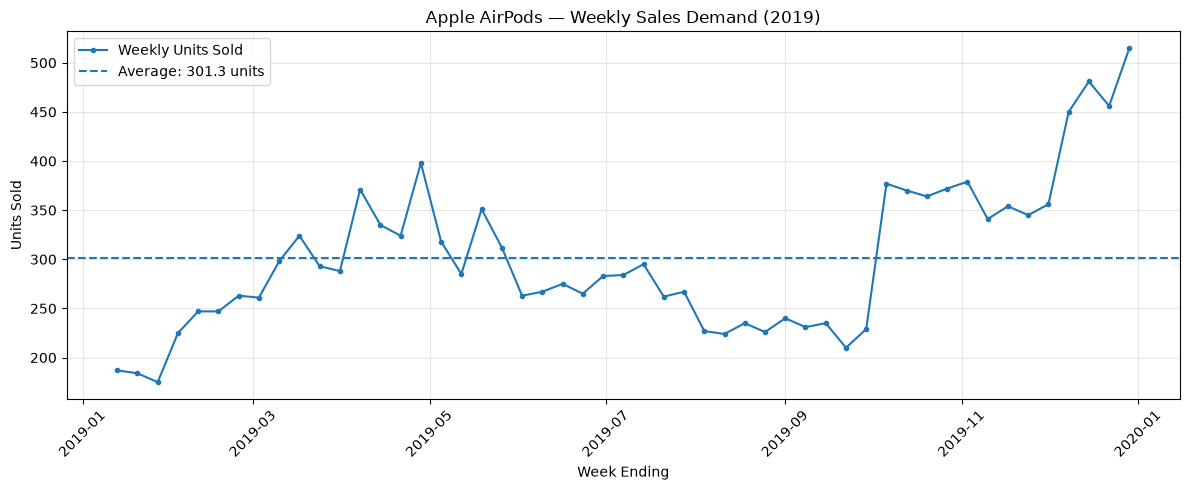

In [11]:

# STEP 21: VISUALIZE APPLE AIRPODS WEEKLY DEMAND

import matplotlib.pyplot as plt

# Select Apple AirPods weekly demand
airpods_weekly = weekly_demand[
    weekly_demand["Product"] == "Apple Airpods Headphones"
].copy()

# Keep only complete 7-day weeks for fair comparison
airpods_full_weeks = airpods_weekly[
    (airpods_weekly["Week_Ending"] >= "2019-01-13") &
    (airpods_weekly["Week_Ending"] <= "2019-12-29")
].copy()

# Calculate average weekly sales
average_demand = airpods_full_weeks["Units_Sold"].mean()

# Create the chart
plt.figure(figsize=(12, 5))

plt.plot(
    airpods_full_weeks["Week_Ending"],
    airpods_full_weeks["Units_Sold"],
    marker="o",
    linewidth=1.5,
    markersize=3,
    label="Weekly Units Sold"
)

# Add an average-demand reference line
plt.axhline(
    y=average_demand,
    linestyle="--",
    label=f"Average: {average_demand:.1f} units"
)

# Chart formatting
plt.title("Apple AirPods — Weekly Sales Demand (2019)")
plt.xlabel("Week Ending")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


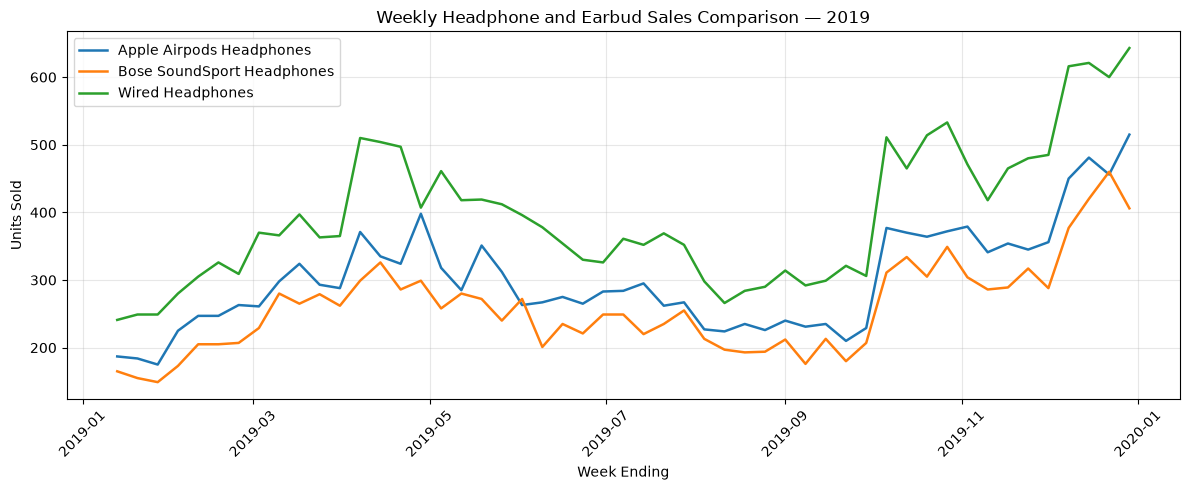

In [12]:

# STEP 22: COMPARE WEEKLY AUDIO PRODUCT DEMAND

import matplotlib.pyplot as plt

# Select the three audio products
audio_comparison = [
    "Apple Airpods Headphones",
    "Bose SoundSport Headphones",
    "Wired Headphones"
]

# Keep only complete weeks
audio_weekly = weekly_demand[
    (weekly_demand["Product"].isin(audio_comparison)) &
    (weekly_demand["Week_Ending"] >= "2019-01-13") &
    (weekly_demand["Week_Ending"] <= "2019-12-29")
].copy()

# Arrange data so each product becomes a separate line
audio_pivot = audio_weekly.pivot(
    index="Week_Ending",
    columns="Product",
    values="Units_Sold"
)

# Create the comparison chart
plt.figure(figsize=(12, 5))

for product in audio_comparison:
    plt.plot(
        audio_pivot.index,
        audio_pivot[product],
        label=product,
        linewidth=1.8
    )

plt.title("Weekly Headphone and Earbud Sales Comparison — 2019")
plt.xlabel("Week Ending")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()



## Product Selection Decision

### Selected Product
Apple Airpods Headphones — Wireless Earbuds

### Historical Sales Findings
- Annual recorded sales: 15,633 units
- Annual recorded revenue: $2,344,950
- Average complete-week sales: 301.3 units
- Complete weekly periods analyzed: 51

### Demand Pattern Observations
- Sales generally increased during early 2019.
- Demand was relatively weaker during the middle of the year.
- All three audio products showed stronger sales toward year-end.
- Weekly fluctuations indicate a need to evaluate demand-planning methods.

### Business Justification
Wireless earbuds were selected because they combine meaningful sales activity, demand variability, and complex hardware supply-chain requirements.

### Planning Implications
Forecasting changes in weekly demand could support inventory replenishment, safety-stock planning, and hypothetical product-launch readiness decisions.

### Limitations
- The source is a Kaggle teaching dataset.
- Sales are not verified Apple operational data.
- One year of observations cannot establish recurring seasonality.
- Sales may differ from unconstrained customer demand.
- Supply, inventory, and launch scenarios will use documented assumptions where actual data is unavailable.

### Decision
Proceed with Apple Airpods Headphones as the primary forecasting product. Retain Bose SoundSport Headphones as a comparison product.


In [13]:
# STEP 23: PREPARE AIRPODS FORECASTING DATASET

# Select AirPods sales from our weekly dataset
df_forecast = weekly_demand[
    weekly_demand["Product"] == "Apple Airpods Headphones"
].copy()

# Keep only complete weeks in 2019
df_forecast = df_forecast[
    (df_forecast["Week_Ending"] >= "2019-01-13") &
    (df_forecast["Week_Ending"] <= "2019-12-29")
].copy()

# Keep the two columns needed for forecasting
df_forecast = df_forecast[
    ["Week_Ending", "Units_Sold"]
]

# Sort by date and reset row numbers
df_forecast = (
    df_forecast
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

# Check data quality
print("===== FORECASTING DATASET CHECK =====")
print("Number of weeks:", len(df_forecast))
print("Missing values:")
print(df_forecast.isna().sum())

print("\nDuplicate dates:",
      df_forecast["Week_Ending"].duplicated().sum())

print("\nAverage weekly units:",
      round(df_forecast["Units_Sold"].mean(), 1))

print("\nFirst five weeks:")
display(df_forecast.head())

print("\nLast five weeks:")
display(df_forecast.tail())


===== FORECASTING DATASET CHECK =====
Number of weeks: 51
Missing values:
Week_Ending    0
Units_Sold     0
dtype: int64

Duplicate dates: 0

Average weekly units: 301.3

First five weeks:


,Week_Ending,Units_Sold
0,2019-01-13,187
1,2019-01-20,184
2,2019-01-27,175
3,2019-02-03,225
4,2019-02-10,247



Last five weeks:


,Week_Ending,Units_Sold
46,2019-12-01,356
47,2019-12-08,450
48,2019-12-15,481
49,2019-12-22,456
50,2019-12-29,515


In [14]:

# STEP 24: EXPORT FORECASTING-READY DATASET

from pathlib import Path

# Create a folder for processed datasets
output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Define the output filename
output_file = output_folder / "airpods_weekly_2019.csv"

# Save our forecasting dataset as a CSV
df_forecast.to_csv(output_file, index=False)

# Confirm the file was created
print("Forecasting dataset saved successfully!")
print("File location:", output_file.resolve())
print("Rows exported:", len(df_forecast))
print("Columns exported:", df_forecast.columns.tolist())


Forecasting dataset saved successfully!
File location: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed/airpods_weekly_2019.csv
Rows exported: 51
Columns exported: ['Week_Ending', 'Units_Sold']
